Description...

In [1]:
import sys
sys.path.append('/lhome/ific/c/ccortesp/Analysis/')

from libs import crudo

import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import yaml

# Styling Plot
crudo.pt.ccortesp_plot_style()

%matplotlib inline
%load_ext autoreload
%autoreload 2

# Run Configuration

In [2]:
RUNS_INFO =  {  'Ar': [ # July 2026
                        # {'run_number': 16047, 'extra': ''    },
                        # {'run_number': 16057, 'extra': ''    },
                        # {'run_number': 16047, 'extra': '20260727'},  # Changes in Irene by Gonzalo
                        # {'run_number': 16057, 'extra': '20260727'}
                      ],

                'Xe': [ # COMPARED TO
                        # {'run_number': 14739, 'extra': ''},
                  
                        # Sept 2026
                        # NO zero suppresion, sample of larger dataset
                        # {'run_number': 16081, 'cath_voltage': 24e3, 'extra': ''},
                        # {'run_number': 16082, 'cath_voltage': 24e3, 'extra': ''},
                        # {'run_number': 16083, 'cath_voltage': 24e3, 'extra': ''},
                        # {'run_number': 16089, 'cath_voltage': 30e3, 'extra': ''},
                        # {'run_number': 16090, 'cath_voltage': 33e3, 'extra': ''},
                        {'run_number': 16090, 'cath_voltage': 33e3, 'extra': 'prod_cuts'},    # S1e_min = 400 PE
                      ]
             }

In [3]:
SELECTION_CRITERIA = {  'Ar': [ ("Multiplicities", lambda x: (x['nS1'].sum() == 1) & (x['nS2'].sum() == 1))
                              , ("S1 Width"      , lambda x: (0      <= x['S1w'].sum() <= 2.5e3 ))    # In [ns]
                              , ("S1 Time"       , lambda x: (1000e3 <= x['S1t'].sum()          ))    # In [ns]
                              , ("S2 Width"      , lambda x: (0      <= x['S2w'].sum() <= 100   ))    # In [μs]
                              , ("S2 Time"       , lambda x: (          x['S2t'].sum() <= 1650e3))    # In [ns]
                              ],  
                             
                        'Xe': [ ("Multiplicities", lambda x: (x['nS1'].sum() == 1) & (x['nS2'].sum() == 1))
                              # , ("S1 Width"      , lambda x: (0      <= x['S1w'].sum() <= 450   ))    # In [ns]
                              # , ("S1 Energy"     , lambda x: (400    <= x['S1e'].sum()          ))    # In [PE]
                              # , ("S2 Time"       , lambda x: (          x['S2t'].sum() <= 1650e3))    # In [ns]
                              ],
                      }

## Reconstructed Data

In [4]:
DORO_DICT = {}
SOPH_DICT = {}

for run in RUNS_INFO['Xe']:
    run_id = run['run_number']
    extra  = run['extra']
    
    # Construct a clean, descriptive dictionary key
    key = f"{run_id}_v{extra}" if extra else f"{run_id}"
    # Load and assign the data
    DORO_DICT[key] = crudo.dm.load_run_data(run_id, trigger2=False, extra=extra)

    # if run_id in [16081, 16082]:
    #     SOPH_DICT[key] = crudo.dm.load_run_data(run_id, key='RECO/Events', trigger2=False, extra=extra)

SEL_DICT = {key : pd.DataFrame() for key in DORO_DICT.keys()}

/DST/Events: Run 16090 successfully loaded with data shape: (251363, 26)


# Selection

In [5]:
for key in DORO_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = DORO_DICT[key]

    # Total number of events
    total_events = doro_df['event'].nunique()
    print(f"  Initially: {total_events} events")

    # Start with full dataset
    temp_df = doro_df.copy()

    # Apply each cut step by step
    for label, condition in SELECTION_CRITERIA['Xe']:

        temp_df = temp_df.groupby('event').filter(condition)
        rem_events  = temp_df['event'].nunique()
        
        print(f"  After {label}: {rem_events} events ({(rem_events / total_events) * 100:.2f}%)")

    # Store final selected data
    SEL_DICT[key] = temp_df.copy()


Run 16090_vprod_cuts:
  Initially: 200047 events
  After Multiplicities: 145854 events (72.91%)


Construct the _active volume_ mask to avoid the cathode

In [6]:
EXTRA_INFO = {}

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    sel_df = SEL_DICT[key]

    # This mask defines the active volume (AV) in Z direction
    if key in ['16081', '16082', '16083']:
        cath_lim = doro_df['DT'].max()
    else:
        cath_lim = crudo.tf.get_cathode_limit(sel_df, n_bins=80, step_back=1)
    z_mask    = (sel_df['DT'] >= 0) & (sel_df['DT'] <= cath_lim)
    cath_mask = (sel_df['DT'] > cath_lim)

    EXTRA_INFO[key] = { 'cath_lim': cath_lim, 'AV_Z_mask': z_mask, 'cath_mask': cath_mask }


Run 16090_vprod_cuts:
Cathode limit = 1447.19 μs


# $S1$ Width

When _glowing_ or light affections to the detector appear, we usually see it in the $S1$ width.

Run 16090_vprod_cuts:
  - IC | S1 Width = [0.20, 10.00] μs
  - Selected | S1 Width = [0.20, 10.00] μs


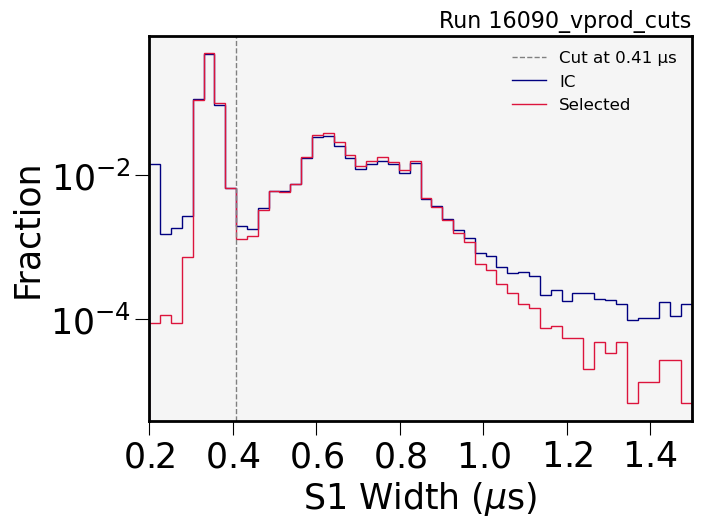

In [7]:
for key in DORO_DICT.keys():

    print(f"Run {key}:")

    edges = []
    for j, (dataframe, label) in enumerate(zip(([DORO_DICT[key], SEL_DICT[key]]), ('IC', 'Selected'))):
        temp_df = dataframe.dropna()   # Do not use events wo S1 pulse

        # Variables
        W1 = temp_df['S1w'] / 1e3   # In [μs]
        print(f"  - {label} | S1 Width = [{W1.min():.2f}, {W1.max():.2f}] μs")

        # Histogram
        # counts, bins, _ = plt.hist(W1, bins=100, range=(W1.min(), W1.max()), histtype='step', color='blue', lw=1.0)
        counts, ex = np.histogram(W1, bins=50, range=(W1.min(), 1.5), density=False)     # There is no significant population above 1.5 μs
        frac = counts / len(temp_df)    # Approx. fraction of all S1 population (not events!)
        
        if j == 0:  edges = ex

        # Plot
        plt.stairs(frac, edges, fill=False, color=crudo.pt.comp_colors[j], lw=1.0, label=label)
        plt.xlabel('S1 Width ($\mu$s)')
        plt.ylabel('Fraction')
        plt.xlim(edges[0], edges[-1])
        plt.yscale('log')
        plt.xticks(np.arange(edges[0], edges[-1], 0.2))

    # Cut line
    S1W_CUT = edges[np.abs(edges - 0.40).argmin()]
    plt.axvline(x=S1W_CUT, c='gray', ls='--', lw=1, label=f'Cut at {S1W_CUT:.2f} μs')
    
    plt.legend(fontsize=12)
    plt.title(f'Run {key}', loc='right', fontsize=16)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

### Cut

In [8]:
COMP_DICT = {key : pd.DataFrame() for key in DORO_DICT.keys()}
LABELS = (f'S1 Width ≤ {S1W_CUT:.2f} μs', f'S1 Width > {S1W_CUT:.2f} μs')

for key in COMP_DICT.keys():

    print(f"\nRun {key}:")
    sel_df = SEL_DICT[key]

    # Total number of events
    total_events = sel_df['event'].nunique()
    print(f"  Initially: {total_events} events")

    # Start with full dataset 
    mask = (sel_df['S1w'] <= S1W_CUT * 1e3)   # In [ns]
    temp_df = sel_df.copy()

    tiny_df = temp_df[mask].copy()
    big_df  = temp_df[~mask].copy()
    print(f"  {LABELS[0]}: {tiny_df['event'].nunique()} events ({(tiny_df['event'].nunique() / total_events) * 100:.2f}%)")
    print(f"  {LABELS[1]}: {big_df['event'].nunique()} events ({(big_df['event'].nunique() / total_events) * 100:.2f}%)")

    COMP_DICT[key] = { 't_s1w': tiny_df.copy(), 'b_s1w': big_df.copy() }


Run 16090_vprod_cuts:
  Initially: 145854 events
  S1 Width ≤ 0.41 μs: 105364 events (72.24%)
  S1 Width > 0.41 μs: 40490 events (27.76%)


In [9]:
tiny_df

,event,time,s1_peak,s2_peak,nS1,nS2,S1w,S1h,S1e,S1t,...,Nsipm,DT,Z,Zrms,X,Y,R,Phi,Xrms,Yrms
0,8,1.790085e+09,0,0,1,1,325.0,258.766266,1493.538818,698775.0,...,134,914.221680,914.221680,12.062181,246.586557,-357.140225,433.997777,-0.966510,33.335525,29.350842
5,43,1.790085e+09,0,0,1,1,375.0,304.204102,1869.581055,631100.0,...,155,982.888428,982.888428,11.835938,154.957836,-319.955442,355.504453,-1.119779,35.738346,34.086308
6,50,1.790085e+09,0,0,1,1,350.0,241.101303,1404.325928,963075.0,...,137,647.921387,647.921387,11.304207,-161.568718,-7.033455,161.721737,-3.098088,33.527048,34.425811
8,71,1.790085e+09,0,0,1,1,325.0,265.227936,1521.456177,623150.0,...,138,989.841797,989.841797,12.115053,-259.688736,-197.922597,326.514309,-2.490359,41.713090,33.473701
10,92,1.790085e+09,0,0,1,1,350.0,319.826233,1899.891846,116425.0,...,124,1498.568481,1498.568481,13.561316,-171.852377,-239.797709,295.018950,-2.192613,28.262822,31.054119
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251328,299033,1.790093e+09,0,0,1,1,350.0,219.599152,1310.619995,1070425.0,...,136,540.569763,540.569763,12.076603,-377.240423,129.159652,398.738702,2.811722,32.093719,31.790856
251329,299047,1.790093e+09,0,0,1,1,350.0,296.765472,1752.448608,108800.0,...,27,1502.201172,1502.201172,10.825202,-439.190552,-115.087468,454.019236,-2.885311,17.157058,19.446122
251336,299075,1.790093e+09,0,0,1,1,325.0,248.365921,1436.809448,881550.0,...,118,730.431641,730.431641,11.809452,79.283044,-88.373855,118.725479,-0.839568,30.419527,27.239545
251337,299089,1.790093e+09,0,0,1,1,350.0,225.597183,1322.920166,1115825.0,...,193,496.140900,496.140900,11.565969,-290.858624,213.388176,360.739868,2.508638,36.576777,41.139504


In [10]:
big_df

,event,time,s1_peak,s2_peak,nS1,nS2,S1w,S1h,S1e,S1t,...,Nsipm,DT,Z,Zrms,X,Y,R,Phi,Xrms,Yrms
1,22,1.790085e+09,0,0,1,1,775.0,338.428711,1968.093018,283675.0,...,156,1330.320679,1330.320679,12.991668,-365.412363,206.995288,419.968147,2.626192,33.381450,35.155480
2,29,1.790085e+09,0,0,1,1,700.0,431.690094,2477.618896,804550.0,...,116,1491.430542,1491.430542,12.215796,-83.540573,17.516692,85.357260,2.934908,27.502425,26.934530
9,78,1.790085e+09,0,0,1,1,575.0,319.917816,1939.596191,296100.0,...,114,1318.870605,1318.870605,38.877724,-409.299583,22.503786,409.917759,3.086667,167.900117,62.713951
13,120,1.790085e+09,0,0,1,1,625.0,241.160141,1367.386719,1080550.0,...,92,530.432129,530.432129,10.687808,356.691777,-294.279417,462.416911,-0.689815,25.249636,29.668326
17,155,1.790085e+09,0,0,1,1,725.0,276.024170,1738.189087,570275.0,...,122,1042.719360,1042.719360,9.774628,270.823902,-329.365798,426.412259,-0.882630,29.247310,28.617327
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251339,299110,1.790093e+09,0,0,1,1,625.0,267.545074,1558.654785,102550.0,...,49,1513.437500,1513.437500,15.347454,-262.924878,-374.021637,457.188885,-2.183511,21.998897,19.866221
251348,299334,1.790093e+09,0,0,1,1,750.0,233.095490,1403.500610,1572425.0,...,113,36.537251,36.537251,10.936065,-278.068127,372.383218,464.748474,2.212199,28.873938,33.340732
251349,299635,1.790093e+09,0,0,1,1,725.0,140.066071,875.041260,1564500.0,...,62,45.503376,45.503376,14.023361,-210.269779,-416.564452,466.625463,-2.038254,31.739835,20.697997
251352,299670,1.790093e+09,0,0,1,1,4675.0,6.674582,590.953003,1540750.0,...,59,65.273750,65.273750,10.657435,-210.020261,-418.849893,468.554951,-2.035580,23.812617,21.227540


## Pulse Characterization


Run 16090_vprod_cuts:
  - Selected | S1 Energy = [400.06, 329299.66] PE
  - S1 Width ≤ 0.41 μs | S1 Energy = [400.06, 15779.26] PE
  - S1 Width > 0.41 μs | S1 Energy = [400.52, 329299.66] PE


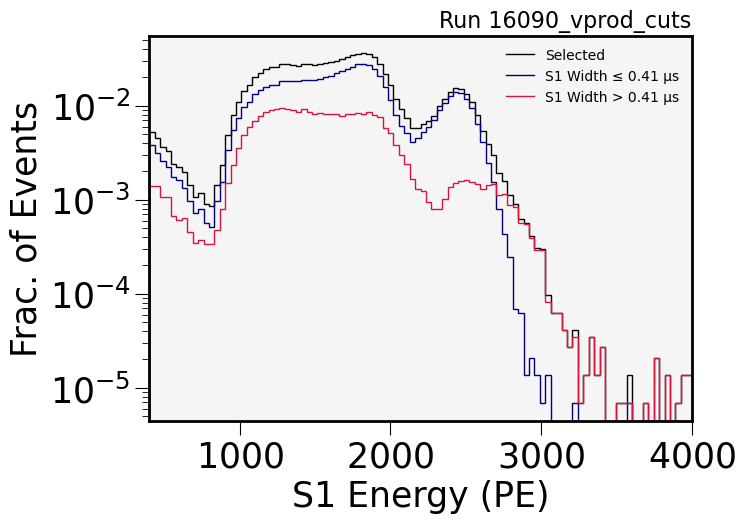

In [9]:
for key in COMP_DICT.keys():

    print(f"\nRun {key}:")

    # Total dataframe
    sel_df = SEL_DICT[key]
    tot_events = sel_df['event'].nunique()

    all_E1 = sel_df['S1e']
    print(f"  - Selected | S1 Energy = [{all_E1.min():.2f}, {all_E1.max():.2f}] PE")

    all_counts, all_ex = np.histogram(all_E1, bins=100, range=(all_E1.min(), 4e3), density=False)
    plt.stairs(all_counts / tot_events, all_ex, fill=False, color='black', lw=1.0, label='Selected')

    dataframes = ([COMP_DICT[key]['t_s1w'], COMP_DICT[key]['b_s1w']])
    for j, (df, lab) in enumerate(zip(dataframes, LABELS)):
        
        # Variables
        E1 = df['S1e']
        print(f"  - {lab} | S1 Energy = [{E1.min():.2f}, {E1.max():.2f}] PE")

        # Histogram
        counts, _ = np.histogram(E1, bins=all_ex)
        frac = counts / tot_events

        # Plot
        plt.stairs(frac, all_ex, fill=False, color=crudo.pt.comp_colors[j], lw=1.0, label=lab)
    
    plt.xlabel('S1 Energy (PE)')
    plt.ylabel('Frac. of Events')
    plt.xlim(all_ex[0], all_ex[-1])
    plt.yscale('log')
    # plt.xticks(np.arange(edges[0], edges[-1], 0.2))
    plt.legend(fontsize=10)
    plt.title(f'Run {key}', loc='right', fontsize=16)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16090_vprod_cuts:
  - Selected | S1 Height = [4.05, 4038.07] PE
  - S1 Width ≤ 0.41 μs | S1 Height = [47.02, 3129.06] PE
  - S1 Width > 0.41 μs | S1 Height = [4.05, 4038.07] PE


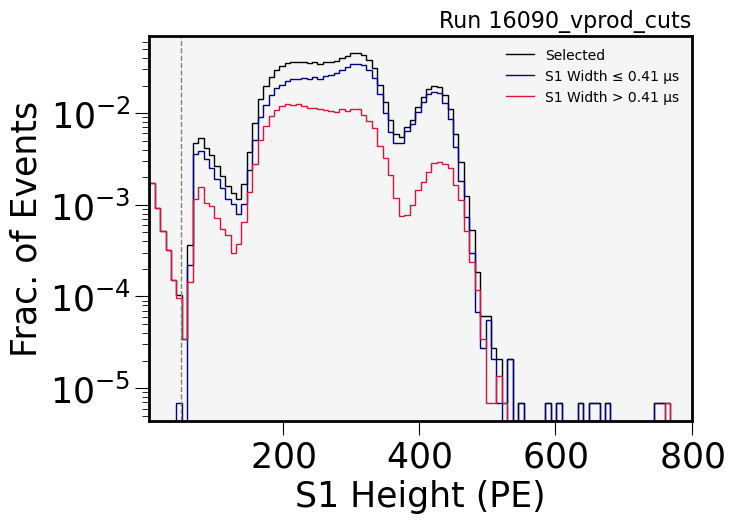

In [10]:
for key in COMP_DICT.keys():

    print(f"\nRun {key}:")

    # Total dataframe
    sel_df = SEL_DICT[key]
    tot_events = sel_df['event'].nunique()

    all_H1 = sel_df['S1h']
    print(f"  - Selected | S1 Height = [{all_H1.min():.2f}, {all_H1.max():.2f}] PE")

    all_counts, all_ex = np.histogram(all_H1, bins=100, range=(all_H1.min(), 800), density=False)
    plt.stairs(all_counts / tot_events, all_ex, fill=False, color='black', lw=1.0, label='Selected')

    dataframes = ([COMP_DICT[key]['t_s1w'], COMP_DICT[key]['b_s1w']])
    for j, (df, lab) in enumerate(zip(dataframes, LABELS)):
        
        # Variables
        H1 = df['S1h']
        print(f"  - {lab} | S1 Height = [{H1.min():.2f}, {H1.max():.2f}] PE")

        # Histogram
        counts, _ = np.histogram(H1, bins=all_ex)
        frac = counts / tot_events

        # Plot
        plt.stairs(frac, all_ex, fill=False, color=crudo.pt.comp_colors[j], lw=1.0, label=lab)

    #
    plt.axvline(x=50, c='gray', ls='--', lw=1)
    
    plt.xlabel('S1 Height (PE)')
    plt.ylabel('Frac. of Events')
    plt.xlim(all_ex[0], all_ex[-1])
    plt.yscale('log')
    # plt.xticks(np.arange(edges[0], edges[-1], 0.2))
    plt.legend(fontsize=10)
    plt.title(f'Run {key}', loc='right', fontsize=16)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16090_vprod_cuts:
  - Selected | S1 Time = [0.03, 1579.67] PE
  - S1 Width ≤ 0.41 μs | S1 Time = [9.88, 1579.67] PE
  - S1 Width > 0.41 μs | S1 Time = [0.03, 1579.53] PE


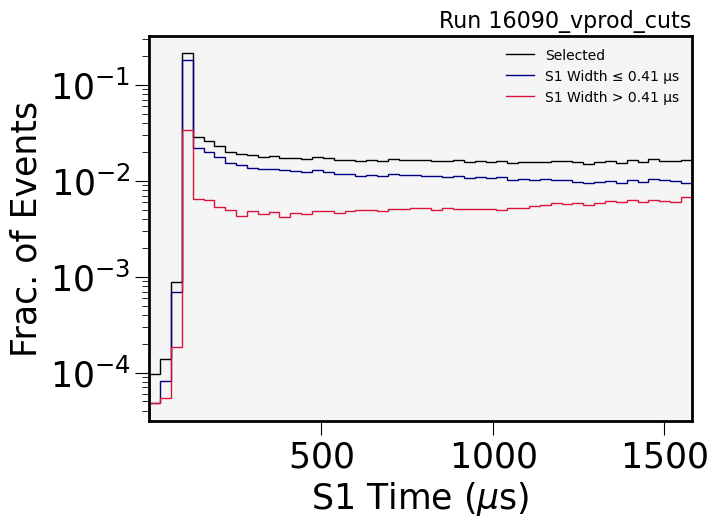

In [11]:
for key in COMP_DICT.keys():

    print(f"\nRun {key}:")

    # Total dataframe
    sel_df = SEL_DICT[key]
    tot_events = sel_df['event'].nunique()

    all_T1 = sel_df['S1t'] / 1e3    # In [μs]
    print(f"  - Selected | S1 Time = [{all_T1.min():.2f}, {all_T1.max():.2f}] PE")

    all_counts, all_ex = np.histogram(all_T1, bins=50, range=(all_T1.min(), all_T1.max()), density=False)
    plt.stairs(all_counts / tot_events, all_ex, fill=False, color='black', lw=1.0, label='Selected')

    dataframes = ([COMP_DICT[key]['t_s1w'], COMP_DICT[key]['b_s1w']])
    for j, (df, lab) in enumerate(zip(dataframes, LABELS)):
        
        # Variables
        T1 = df['S1t'] / 1e3
        print(f"  - {lab} | S1 Time = [{T1.min():.2f}, {T1.max():.2f}] PE")

        # Histogram
        counts, _ = np.histogram(T1, bins=all_ex)
        frac = counts / tot_events

        # Plot
        plt.stairs(frac, all_ex, fill=False, color=crudo.pt.comp_colors[j], lw=1.0, label=lab)

    #
    # plt.axvline(x=50, c='gray', ls='--', lw=1)
    
    plt.xlabel('S1 Time ($\mu$s)')
    plt.ylabel('Frac. of Events')
    plt.xlim(all_ex[0], all_ex[-1])
    plt.yscale('log')
    # plt.xticks(np.arange(edges[0], edges[-1], 0.2))
    plt.legend(fontsize=10)
    plt.title(f'Run {key}', loc='right', fontsize=16)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()


Run 16090_vprod_cuts:


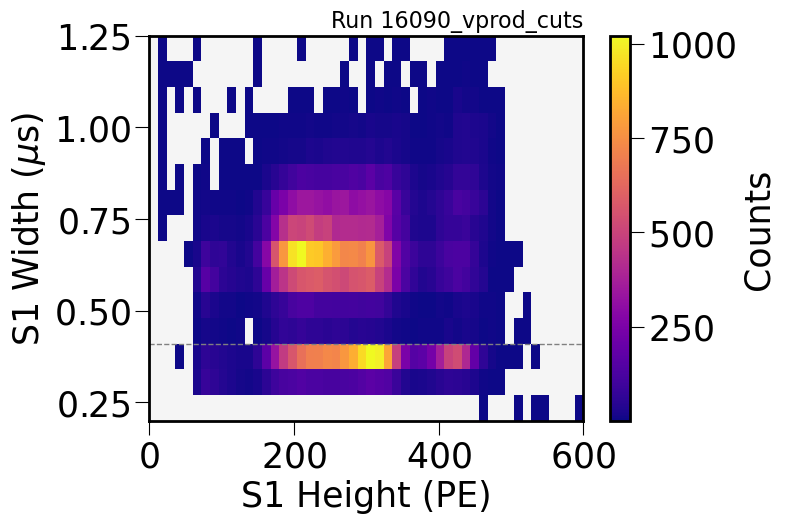

In [12]:
for key in COMP_DICT.keys():

    print(f"\nRun {key}:")
    sel_df = SEL_DICT[key]

    # Variables    
    all_W1 = sel_df['S1w'] / 1e3
    all_H1 = sel_df['S1h']

    # 2D Histogram
    _, ex, ey = np.histogram2d(all_H1, all_W1, bins=[50, 15], range=[(0, 600), (0.2, 1.25)])

    dataframes = ([COMP_DICT[key]['t_s1w'], COMP_DICT[key]['b_s1w']])
    for j, (df, lab) in enumerate(zip(dataframes, LABELS)):

        # Variables    
        W1 = df['S1w'] / 1e3
        H1 = df['S1h']

        # 2D Histogram
        s1w_s1h_map, _, _ = np.histogram2d(H1, W1, bins=[ex, ey])
        s1w_s1h_map       = np.ma.masked_where(s1w_s1h_map==0, s1w_s1h_map)

        # Plot
        plt.pcolormesh(ex, ey, s1w_s1h_map.T, cmap='plasma', shading='auto')

    #
    plt.axhline(y=S1W_CUT, c='gray', ls='--', lw=1)
    
    #
    plt.colorbar(label='Counts')
    plt.xlabel('S1 Height (PE)')
    plt.ylabel('S1 Width ($\mu$s)')
    plt.xlim(ex[0], ex[-1])
    # plt.ylim(0.2, 1.0)
    # plt.yscale('log')
    # plt.xticks(np.arange(edges[0], edges[-1], 0.2))
    plt.title(f'Run {key}', loc='right', fontsize=16)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

# $S1$ Multiplicity

Run 16090_vprod_cuts:


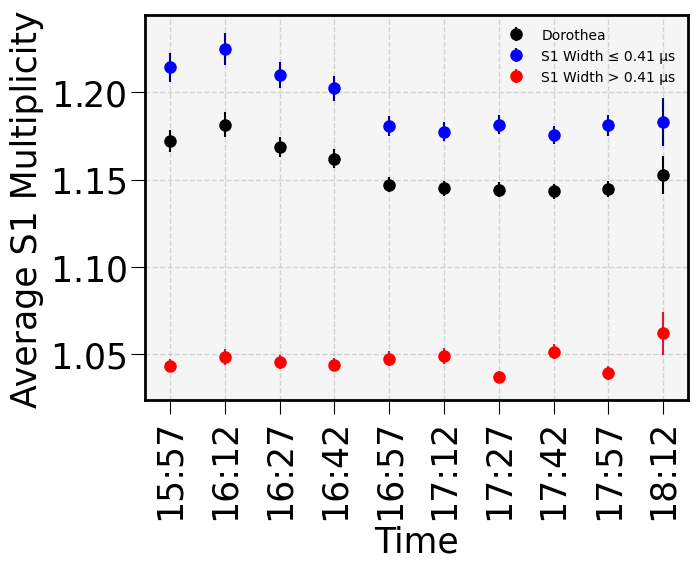

In [13]:
# Global
kwargs = {
            "variable"    : "nS1",
            "method"      : "first",
            "stat_method" : "mean",
            "stat_err"    : "sem",
            "hour_parts"  : 4,
        }

for key in DORO_DICT.keys():

    print(f"Run {key}:")

    doro_df = DORO_DICT[key]
    doro_df = doro_df.dropna()   # Do not use events wo S1 pulse
    tot_events = doro_df['event'].nunique()

    # S1w classification
    tiny_event_ids = doro_df.loc[doro_df["S1w"] <= S1W_CUT * 1e3, "event"].unique()
    tiny_df = doro_df[doro_df["event"].isin(tiny_event_ids)]
    big_df = doro_df[~doro_df["event"].isin(tiny_event_ids)]

    # ---
    doro_stat = crudo.ut.calculate_hourly_stats(doro_df, **kwargs)
    tiny_stat = crudo.ut.calculate_hourly_stats(tiny_df, **kwargs)
    big_stat  = crudo.ut.calculate_hourly_stats(big_df, **kwargs)

    plt.errorbar( doro_stat['time_cv'], doro_stat['nS1_cv'], yerr=doro_stat['nS1_err']
                , fmt='o', c='black', ecolor='black', elinewidth=1.5, label='Dorothea' )
    plt.errorbar( tiny_stat['time_cv'], tiny_stat['nS1_cv'], yerr=tiny_stat['nS1_err']
                , fmt='o', c='blue', ecolor='navy', elinewidth=1.5, label=LABELS[0])
    plt.errorbar( big_stat['time_cv'], big_stat['nS1_cv'], yerr=big_stat['nS1_err']
                , fmt='o', c='red', ecolor='crimson', elinewidth=1.5, label=LABELS[1])

    x_labels = [crudo.ut.epoch_converter(t, h=True) for t in doro_stat['time_cv']]
    plt.xticks(doro_stat['time_cv'], x_labels, rotation=90)
    plt.xlabel('Time')
    plt.ylabel('Average S1 Multiplicity')
    # plt.ylim(0.8, 1.3)
    plt.legend(fontsize=10)

    plt.grid(True)
    plt.gca().set_facecolor("whitesmoke")
    plt.show()